Running 10000 simulations... This may take 1-2 minutes.
Image saved to outputs/figures/fwer_simulation_advanced.png


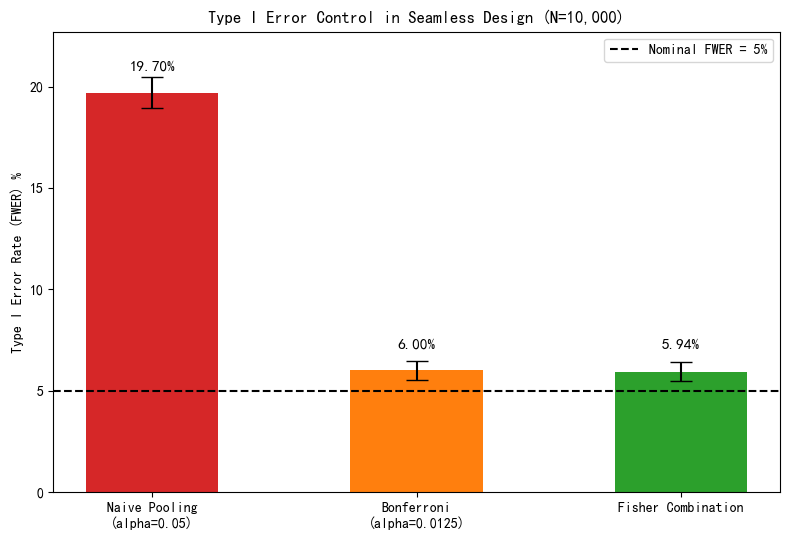

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

def simulate_fwer_advanced(n_sim=10000, alpha_adj=0.0125):
    """
    模拟双终点 FWER 膨胀与校正，加入 Fisher Combination Test
    """
    # 使用 common random numbers 复用于多场景对比（固定 seed）
    rng = np.random.default_rng(1128)
    
    sd = 0.5
    placebo_mean = 1.31
    n_stage1, n_stage2 = 120, 285
    
    reject_naive = 0
    reject_bonf = 0
    reject_fisher = 0
    
    # 进度提示
    print(f"Running {n_sim} simulations... This may take 1-2 minutes.")
    
    for i in range(n_sim):
        # 为了演示 FWER，所有药物都假设为无效（H0成立）
        # Stage 1: 假设 4 个剂量
        s1_doses_trough = [rng.normal(placebo_mean, sd, n_stage1) for _ in range(4)]
        s1_doses_auc = [rng.normal(placebo_mean, sd, n_stage1) for _ in range(4)]
        s1_pbo_trough = rng.normal(placebo_mean, sd, n_stage1)
        s1_pbo_auc = rng.normal(placebo_mean, sd, n_stage1)
        
        # 期中选剂量（基于 Trough 均值）
        means = [d.mean() for d in s1_doses_trough]
        selected_idx = np.argsort(means)[-2:] # 选最高的两个
        
        # Stage 2
        s2_doses_trough = [rng.normal(placebo_mean, sd, n_stage2) for _ in selected_idx]
        s2_doses_auc = [rng.normal(placebo_mean, sd, n_stage2) for _ in selected_idx]
        s2_pbo_trough = rng.normal(placebo_mean, sd, n_stage2)
        s2_pbo_auc = rng.normal(placebo_mean, sd, n_stage2)
        
        # 合并 Stage 1 和 Stage 2
        comb_pbo_trough = np.concatenate([s1_pbo_trough, s2_pbo_trough])
        comb_pbo_auc = np.concatenate([s1_pbo_auc, s2_pbo_auc])
        
        # 为了演示 4 次检验（2 剂量 × 2 终点），我们用 any-rejection
        naive_flag = False
        bonf_flag = False
        fisher_flag = False
        
        for i_dose, idx in enumerate(selected_idx):
            # 终点 1: Trough
            s1_merged_t = s1_doses_trough[idx]
            s2_merged_t = s2_doses_trough[i_dose]
            comb_merged_t = np.concatenate([s1_merged_t, s2_merged_t])
            
            # 终点 2: AUC
            s1_merged_a = s1_doses_auc[idx]
            s2_merged_a = s2_doses_auc[i_dose]
            comb_merged_a = np.concatenate([s1_merged_a, s2_merged_a])
            
            # 1. Naive 分析 (直接合并, α=0.05)
            _, p_naive_t = stats.ttest_ind(comb_merged_t, comb_pbo_trough, equal_var=False, alternative='greater')
            _, p_naive_a = stats.ttest_ind(comb_merged_a, comb_pbo_auc, equal_var=False, alternative='greater')
            
            # 2. Bonferroni 分析 (直接合并, α=0.0125)
            if p_naive_t < 0.0125 or p_naive_a < 0.0125:
                bonf_flag = True
            
            if p_naive_t < 0.05 or p_naive_a < 0.05:
                naive_flag = True
                
            # 3. Fisher Combination Test (基于 Stage 1 和 Stage 2 独立的 p 值)
            # 计算 Stage 1 的 p 值
            _, p1_t = stats.ttest_ind(s1_merged_t, s1_pbo_trough, equal_var=False, alternative='greater')
            _, p1_a = stats.ttest_ind(s1_merged_a, s1_pbo_auc, equal_var=False, alternative='greater')
            
            # 计算 Stage 2 的 p 值
            _, p2_t = stats.ttest_ind(s2_merged_t, s2_pbo_trough, equal_var=False, alternative='greater')
            _, p2_a = stats.ttest_ind(s2_merged_a, s2_pbo_auc, equal_var=False, alternative='greater')
            
            # Fisher 组合: -2 * ln(p1 * p2) ~ Chi-square(df=4)
            def fisher_comb(p1, p2):
                if p1 == 0 or p2 == 0: return 0.0
                stat = -2 * (np.log(p1) + np.log(p2))
                return 1 - stats.chi2.cdf(stat, df=4)
            
            p_fisher_t = fisher_comb(p1_t, p2_t)
            p_fisher_a = fisher_comb(p1_a, p2_a)
            
            # Fisher 组合检验通常不需要再除 4，因为它自带控制，或者用极度严格的 alpha
            if p_fisher_t < 0.0125 or p_fisher_a < 0.0125:
                fisher_flag = True
                
        if naive_flag: reject_naive += 1
        if bonf_flag: reject_bonf += 1
        if fisher_flag: reject_fisher += 1

    # 计算 FWER 和 95% CI (使用正态近似)
    def get_ci(p, n):
        se = np.sqrt(p * (1 - p) / n)
        return p, (p - 1.96*se, p + 1.96*se)

    fwer_naive, ci_naive = get_ci(reject_naive / n_sim, n_sim)
    fwer_bonf, ci_bonf = get_ci(reject_bonf / n_sim, n_sim)
    fwer_fisher, ci_fisher = get_ci(reject_fisher / n_sim, n_sim)
    
    return (fwer_naive, ci_naive), (fwer_bonf, ci_bonf), (fwer_fisher, ci_fisher)

# 跑 10000 次
(naive, ci_n), (bonf, ci_b), (fisher, ci_f) = simulate_fwer_advanced(n_sim=10000)

# 画图（带置信区间误差棒）
labels = ['Naive Pooling\n(alpha=0.05)', 'Bonferroni\n(alpha=0.0125)', 'Fisher Combination']
means = [naive*100, bonf*100, fisher*100]
errors = [(naive*100 - ci_n[0]*100, ci_n[1]*100 - naive*100), 
          (bonf*100 - ci_b[0]*100, ci_b[1]*100 - bonf*100),
          (fisher*100 - ci_f[0]*100, ci_f[1]*100 - fisher*100)]
errors = np.array(errors).T  # 转置成 matplotlib 要求的 2xN 格式

plt.figure(figsize=(8, 5.5))
bars = plt.bar(labels, means, yerr=errors, capsize=8, color=['#d62728', '#ff7f0e', '#2ca02c'], width=0.5)
plt.axhline(5, color='black', linestyle='--', label='Nominal FWER = 5%')

for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width()/2, mean + 1, f'{mean:.2f}%', ha='center', va='bottom', fontsize=11)

plt.ylabel('Type I Error Rate (FWER) %')
plt.title('Type I Error Control in Seamless Design (N=10,000)')
plt.ylim(0, max(means) + 3)
plt.legend()
plt.tight_layout()

plt.savefig('outputs/figures/fwer_simulation_advanced.png', dpi=150)
print("Image saved to outputs/figures/fwer_simulation_advanced.png")
plt.show()